Centralized (re-scored): acc 0.7920 | macro-F1 0.6225   <- should match your notebook (0.7920 / 0.6225)

=== Test metrics ===
                                 accuracy  macro_precision  macro_recall  macro_f1  weighted_f1
model                                                                                         
Centralized                       0.7920           0.6467        0.6188    0.6225       0.7974
FedAvg global (best-val round)    0.7453           0.5680        0.5904    0.5680       0.7607
FedAvg global (last round)        0.7542           0.5635        0.6028    0.5744       0.7675
FL Client 0 (round 30)            0.7562           0.5666        0.6037    0.5766       0.7691
FL Client 1 (round 30)            0.7532           0.5636        0.6032    0.5745       0.7672
FL Client 2 (round 30)            0.7532           0.5691        0.6062    0.5798       0.7664

=== Bootstrap 95% CI (1000 resamples; FL = FedAvg global (best-val round)) ===
   metric             centralized

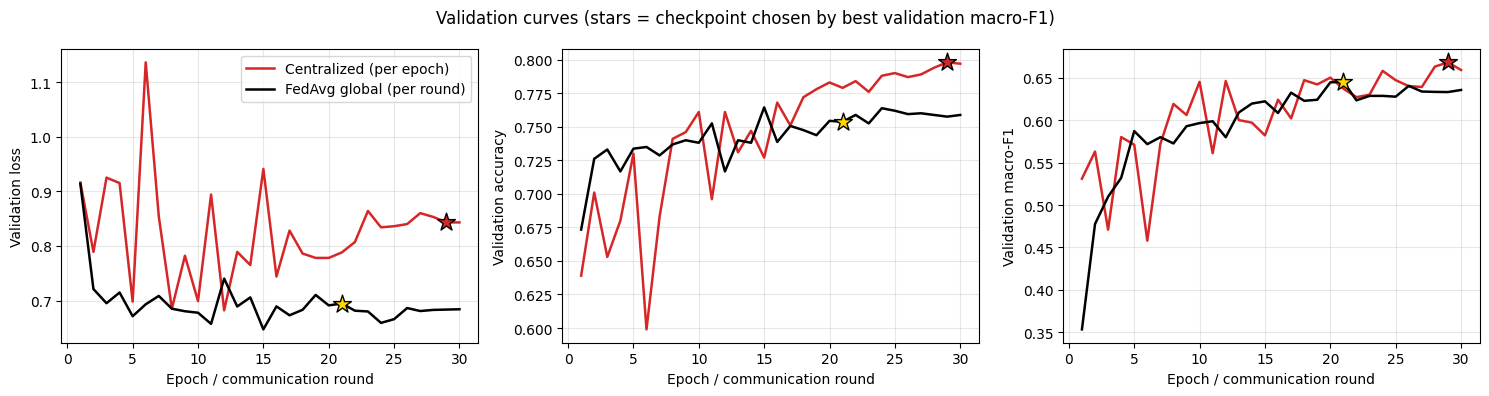

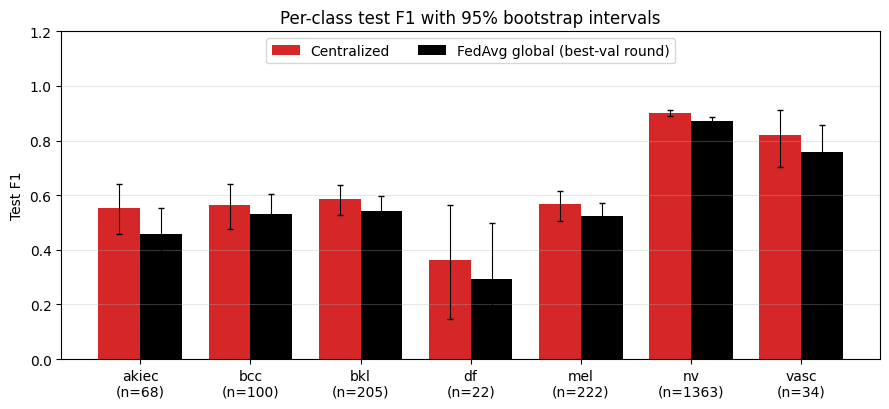

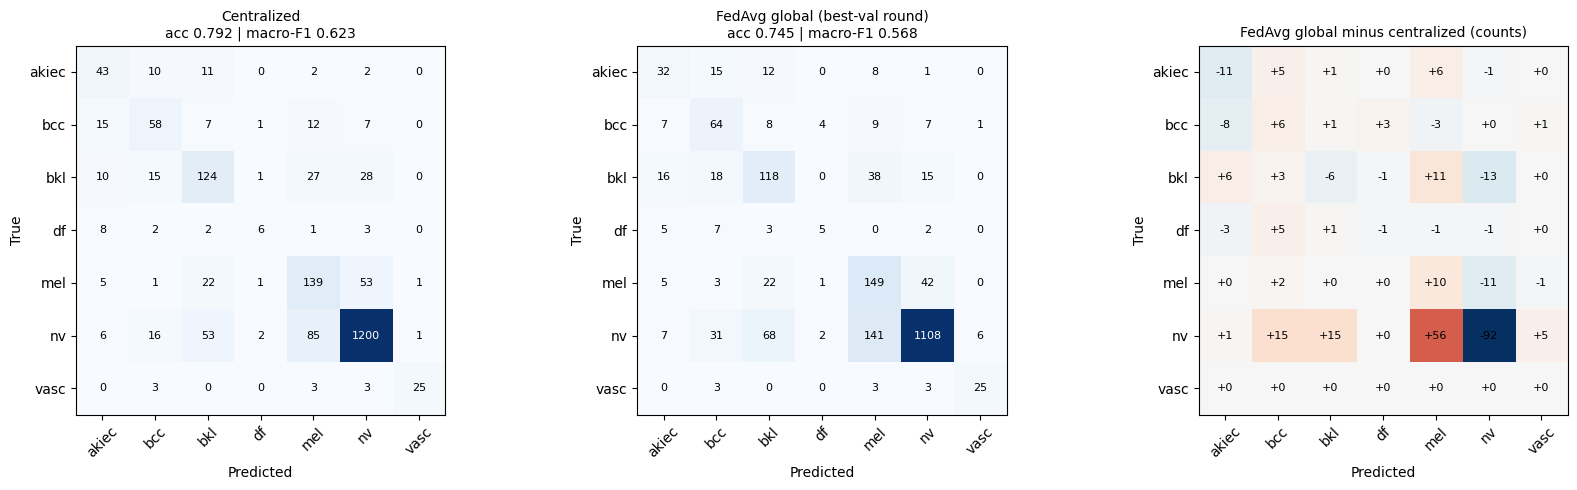


Saved: cmp_curves.png, cmp_per_class_f1.png, cmp_confusion.png, cmp_metrics.csv, cmp_per_class.csv, cmp_bootstrap.csv


In [1]:
"""
Compare the centralized baseline with the aligned 30-round FedAvg baseline.

Run from your "federated learning" folder (dataset/, split_val.csv, split_test.csv, common.py, shared/,
the FL output folder, mobilenetv3_small_baseline.pth and baseline_mobilenetv3.ipynb all reachable):

    python compare_central_vs_fl.py
    python compare_central_vs_fl.py --fl_out outputs_aligned_seed42 --central_pth mobilenetv3_small_baseline.pth \
                                    --central_nb baseline_mobilenetv3.ipynb         # explicit paths
(also works inside a Jupyter cell)

What it does
  1. Scores the saved centralized checkpoint on the test set with the SAME code path the FL server uses
     (common.evaluate), so both models are measured identically. Check that it prints ~0.7920 / ~0.6225.
  2. Reads the FL global model's test predictions written by the new server.py
     (test_predictions_best_val.csv = best-validation round, test_predictions_last_round.csv).
  3. Optionally scores each client's final-round model (needs shared/ from this run; --skip_clients to skip).
  4. Bootstrap (resampling the 2,014 test images, same resample for both models = paired) gives 95% confidence
     intervals for accuracy, macro-F1 and per-class F1, and for the FL-minus-centralized difference.
     A difference whose interval excludes 0 is unlikely to be test-set sampling noise.
     (It does NOT capture training-seed variance; that needs repeated runs.)

Outputs: cmp_curves.png, cmp_per_class_f1.png, cmp_confusion.png,
         cmp_metrics.csv, cmp_per_class.csv, cmp_bootstrap.csv
"""
import os, sys, re, json, argparse
from pathlib import Path

os.environ.setdefault("DATA_ROOT", ".")
sys.path.insert(0, ".")

ap = argparse.ArgumentParser()
ap.add_argument("--central_pth", default="mobilenetv3_small_baseline.pth")
ap.add_argument("--central_nb", default="baseline_mobilenetv3.ipynb")
ap.add_argument("--fl_out", default="outputs_aligned_seed42" if Path("outputs_aligned_seed42").exists() else "outputs_aligned")
ap.add_argument("--shared", default="shared")
ap.add_argument("--n_boot", type=int, default=1000)
ap.add_argument("--skip_clients", action="store_true")
args, _ = ap.parse_known_args()          # known_args so it also runs inside Jupyter

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, f1_score
from common import load_frame, build_model, evaluate, CLASSES

FL_OUT, SHARED_DIR = Path(args.fl_out), Path(args.shared)
K = len(CLASSES)
torch.set_num_threads(os.cpu_count())
test_df = load_frame("split_test.csv")

# ------------------------------------------------------------------ 1) centralized: score the checkpoint
model = build_model()
sd = torch.load(args.central_pth, map_location="cpu")
if isinstance(sd, dict) and "state_dict" in sd: sd = sd["state_dict"]
model.load_state_dict(sd)
_, c_acc, c_f1, c_pred, c_lab = evaluate(model, test_df)
c_pred, c_lab = np.array(c_pred), np.array(c_lab)
print(f"Centralized (re-scored): acc {c_acc:.4f} | macro-F1 {c_f1:.4f}   <- should match your notebook (0.7920 / 0.6225)")

# ------------------------------------------------------------------ 2) FL global predictions from the server
def load_preds(tag):
    f = FL_OUT / f"test_predictions_{tag}.csv"
    if not f.exists(): return None
    d = pd.read_csv(f)
    return d["label"].to_numpy(), d["pred"].to_numpy()

fl = {}
for tag, name in [("best_val", "FedAvg global (best-val round)"), ("last_round", "FedAvg global (last round)")]:
    p = load_preds(tag)
    if p is not None:
        assert (p[0] == c_lab).all(), "test label order differs between centralized and FL - check the split files"
        fl[name] = p[1]
if not fl:
    sys.exit(f"No test_predictions_*.csv in {FL_OUT} - run the NEW server.py first.")
main_name = "FedAvg global (best-val round)" if "FedAvg global (best-val round)" in fl else list(fl)[0]
best_round = None
if (FL_OUT / "final_metrics.json").exists():
    fm = json.loads((FL_OUT / "final_metrics.json").read_text()); best_round = fm["best_val"]["round"]

# ------------------------------------------------------------------ 3) optional: client models at the final round
hist = pd.read_csv(FL_OUT / "fedavg_history.csv")
R = int(hist["round"].max())
clients = {}
if not args.skip_clients:
    for c in range(3):
        f = SHARED_DIR / f"client{c}_round{R}.pt"
        if f.exists():
            model.load_state_dict(torch.load(f, map_location="cpu")["state"])
            _, _, _, pr, lb = evaluate(model, test_df)
            clients[f"FL Client {c} (round {R})"] = np.array(pr)
        else:
            print("skipping client", c, "- not found:", f)

# ------------------------------------------------------------------ metrics table
def summary(y, p):
    P, Rr, F, _ = precision_recall_fscore_support(y, p, labels=range(K), average="macro", zero_division=0)
    wF = precision_recall_fscore_support(y, p, labels=range(K), average="weighted", zero_division=0)[2]
    return dict(accuracy=float(np.mean(y == p)), macro_precision=P, macro_recall=Rr, macro_f1=F, weighted_f1=wF)

models = {"Centralized": c_pred, **fl, **clients}
tab = pd.DataFrame({k: summary(c_lab, v) for k, v in models.items()}).T.round(4)
tab.index.name = "model"; tab.to_csv("cmp_metrics.csv")
print("\n=== Test metrics ===\n", tab.to_string())

pcF1 = {k: f1_score(c_lab, v, labels=range(K), average=None, zero_division=0) for k, v in models.items()}
support = np.bincount(c_lab, minlength=K)

# ------------------------------------------------------------------ 4) paired bootstrap on the test set
rng = np.random.default_rng(0)
n = len(c_lab); B = args.n_boot
fl_pred = fl[main_name]
accs = np.zeros((B, 2)); f1s = np.zeros((B, K, 2))
for b in range(B):
    i = rng.integers(0, n, n)
    for m, pr in enumerate((c_pred, fl_pred)):
        accs[b, m] = np.mean(c_lab[i] == pr[i])
        f1s[b, :, m] = f1_score(c_lab[i], pr[i], labels=range(K), average=None, zero_division=0)
mac = f1s.mean(1)                                            # macro-F1 per resample, shape (B, 2)
ci = lambda a: np.percentile(a, [2.5, 97.5])

rows = []
for label, arr, point in [("accuracy", accs, (summary(c_lab, c_pred)["accuracy"], summary(c_lab, fl_pred)["accuracy"])),
                          ("macro_f1", mac, (summary(c_lab, c_pred)["macro_f1"], summary(c_lab, fl_pred)["macro_f1"]))]:
    d = arr[:, 1] - arr[:, 0]; lo, hi = ci(d)
    rows.append(dict(metric=label,
                     centralized=f"{point[0]:.4f} [{ci(arr[:,0])[0]:.4f}, {ci(arr[:,0])[1]:.4f}]",
                     fl=f"{point[1]:.4f} [{ci(arr[:,1])[0]:.4f}, {ci(arr[:,1])[1]:.4f}]",
                     diff_fl_minus_central=round(point[1] - point[0], 4), diff_ci_low=round(lo, 4), diff_ci_high=round(hi, 4),
                     excludes_zero=bool(lo > 0 or hi < 0)))
boot = pd.DataFrame(rows); boot.to_csv("cmp_bootstrap.csv", index=False)
print(f"\n=== Bootstrap 95% CI ({B} resamples; FL = {main_name}) ===\n", boot.to_string(index=False))

pc_rows = []
for k, cl in enumerate(CLASSES):
    d = f1s[:, k, 1] - f1s[:, k, 0]; lo, hi = ci(d)
    pc_rows.append(dict(cls=cl, support=int(support[k]), f1_central=pcF1["Centralized"][k], f1_fl=pcF1[main_name][k],
                        diff=pcF1[main_name][k] - pcF1["Centralized"][k], ci_low=lo, ci_high=hi,
                        excludes_zero=bool(lo > 0 or hi < 0)))
pc = pd.DataFrame(pc_rows).round(3); pc.to_csv("cmp_per_class.csv", index=False)
print("\n=== Per-class F1 (diff = FL - centralized, paired bootstrap 95% CI) ===\n", pc.to_string(index=False))

# ------------------------------------------------------------------ plots
# (a) validation curves: centralized per epoch vs FL global per round
cen = None
if Path(args.central_nb).exists():
    nb = json.loads(Path(args.central_nb).read_text(encoding="utf-8"))
    txt = "".join("".join(o.get("text", [])) for c in nb["cells"] for o in c.get("outputs", []))
    pat = re.compile(r"Epoch (\d+)/\d+ \| train loss ([\d.]+) acc ([\d.]+) \| val loss ([\d.]+) acc ([\d.]+) macroF1 ([\d.]+)")
    ep = {int(m[0]): [float(x) for x in m[1:]] for m in pat.findall(txt)}
    if ep:
        cen = pd.DataFrame([[e] + v for e, v in sorted(ep.items())], columns=["epoch", "tl", "ta", "vl", "va", "vf"])
if cen is None:
    print("\n(no per-epoch log found in the notebook output - skipping the curves figure)")
else:
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for a, (cc, fc, yl) in zip(ax, [("vl", "val_loss", "Validation loss"), ("va", "val_acc", "Validation accuracy"),
                                    ("vf", "val_macro_f1", "Validation macro-F1")]):
        a.plot(cen["epoch"], cen[cc], color="tab:red", lw=1.8, label="Centralized (per epoch)")
        a.plot(hist["round"], hist[fc], color="black", lw=1.8, label="FedAvg global (per round)")
        be = cen.loc[cen["vf"].idxmax()]
        a.scatter([be["epoch"]], [be[cc]], marker="*", s=180, color="tab:red", edgecolor="black", zorder=5)
        if best_round: a.scatter([best_round], [hist.loc[hist["round"] == best_round, fc].iloc[0]], marker="*", s=180,
                                 color="gold", edgecolor="black", zorder=5)
        a.set_xlabel("Epoch / communication round"); a.set_ylabel(yl); a.grid(alpha=.3)
    ax[0].legend(); fig.suptitle("Validation curves (stars = checkpoint chosen by best validation macro-F1)")
    plt.tight_layout(); plt.savefig("cmp_curves.png", dpi=200); plt.show()

# (b) per-class F1 with bootstrap CIs
fig, ax = plt.subplots(figsize=(9, 4.2)); x = np.arange(K); w = 0.38
for m, (name, col, off) in enumerate([("Centralized", "tab:red", -w / 2), (main_name, "black", w / 2)]):
    pt = pcF1[name]; lo, hi = np.percentile(f1s[:, :, m], 2.5, axis=0), np.percentile(f1s[:, :, m], 97.5, axis=0)
    ax.bar(x + off, pt, w, color=col, label=name, yerr=[pt - lo, hi - pt], capsize=2, error_kw=dict(lw=.8))
ax.set_xticks(x); ax.set_xticklabels([f"{c}\n(n={s})" for c, s in zip(CLASSES, support)])
ax.set_ylabel("Test F1"); ax.set_ylim(0, 1.2); ax.grid(axis="y", alpha=.3); ax.legend(loc="upper center", ncol=2)
ax.set_title("Per-class test F1 with 95% bootstrap intervals")
plt.tight_layout(); plt.savefig("cmp_per_class_f1.png", dpi=200); plt.show()

# (c) confusion matrices: centralized, FL global, and FL - centralized
cm_c = confusion_matrix(c_lab, c_pred, labels=range(K)); cm_f = confusion_matrix(c_lab, fl_pred, labels=range(K))
diff = cm_f - cm_c
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax_, cm, title in [(axes[0], cm_c, f"Centralized\nacc {summary(c_lab, c_pred)['accuracy']:.3f} | macro-F1 {summary(c_lab, c_pred)['macro_f1']:.3f}"),
                       (axes[1], cm_f, f"{main_name}\nacc {summary(c_lab, fl_pred)['accuracy']:.3f} | macro-F1 {summary(c_lab, fl_pred)['macro_f1']:.3f}")]:
    ax_.imshow(cm, cmap="Blues"); ax_.set_title(title, fontsize=10)
    for i in range(K):
        for j in range(K):
            ax_.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
v = max(1, np.abs(diff).max())
axes[2].imshow(diff, cmap="RdBu_r", norm=TwoSlopeNorm(0, -v, v)); axes[2].set_title("FedAvg global minus centralized (counts)", fontsize=10)
for i in range(K):
    for j in range(K):
        axes[2].text(j, i, f"{diff[i, j]:+d}", ha="center", va="center", fontsize=8)
for ax_ in axes:
    ax_.set_xticks(range(K)); ax_.set_xticklabels(CLASSES, rotation=45); ax_.set_yticks(range(K)); ax_.set_yticklabels(CLASSES)
    ax_.set_xlabel("Predicted"); ax_.set_ylabel("True")
plt.tight_layout(); plt.savefig("cmp_confusion.png", dpi=200); plt.show()
print("\nSaved: cmp_curves.png, cmp_per_class_f1.png, cmp_confusion.png, cmp_metrics.csv, cmp_per_class.csv, cmp_bootstrap.csv")

                            rounds  mean  std  min  max  slowdown_vs_fastest
client                                                                      
Client 0 (1.0 CPU, 1 GB)        30  56.9  4.8   51   70                 1.16
Client 1 (0.5 CPU, 768 MB)      30  75.3  5.4   69   91                 1.53
Client 2 (2.0 CPU, 1.5 GB)      30  49.2  4.2   44   59                 1.00

mean full round time (server, waits for slowest client): 102s


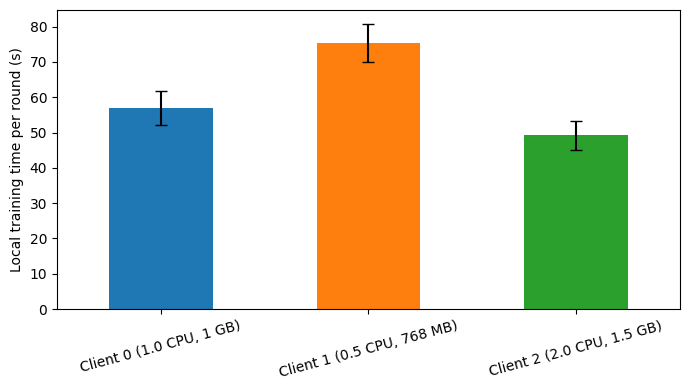

In [2]:
import re, subprocess
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

FL_OUT = Path("outputs_aligned_seed42")          # your new run's output folder
CLIENTS = {0: ("edge0", "1.0 CPU, 1 GB"), 1: ("edge1", "0.5 CPU, 768 MB"), 2: ("edge2", "2.0 CPU, 1.5 GB")}
pat = re.compile(r"\[client (\d+)\] round (\d+)/\d+ .*\| (\d+)s")      # "... | 123s" = local training time of that round

rows = []
for cid, (container, limits) in CLIENTS.items():
    try:                                                                # live container logs ...
        r = subprocess.run(["docker", "logs", container], capture_output=True, text=True, check=True)
        text = r.stdout + r.stderr
    except Exception:                                                   # ... or a saved copy: docker logs edge0 > edge0.log
        f = Path(f"{container}.log"); text = f.read_text() if f.exists() else ""
    for c, rnd, sec in pat.findall(text):
        rows.append(dict(client=f"Client {c} ({limits})", round=int(rnd), seconds=int(sec)))

t = pd.DataFrame(rows).drop_duplicates(["client", "round"], keep="last")
summary = t.groupby("client")["seconds"].agg(rounds="count", mean="mean", std="std", min="min", max="max").round(1)
summary["slowdown_vs_fastest"] = (summary["mean"] / summary["mean"].min()).round(2)
print(summary.to_string())
if (FL_OUT / "fedavg_history.csv").exists():
    print(f"\nmean full round time (server, waits for slowest client): {pd.read_csv(FL_OUT / 'fedavg_history.csv')['round_seconds'].mean():.0f}s")

ax = summary["mean"].plot.bar(yerr=summary["std"], capsize=4, color=["tab:blue", "tab:orange", "tab:green"], figsize=(7, 4))
ax.set_ylabel("Local training time per round (s)"); ax.set_xlabel(""); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

In [3]:
ax.figure.savefig("client_training_time.png", dpi=200, bbox_inches="tight"); open("client_training_time.txt", "w").write(summary.to_string())

384